In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import warnings
warnings.filterwarnings("ignore")

In [2]:
from google.colab import files

uploaded = files.upload()

Saving profitlens_business_dataset_10000.csv to profitlens_business_dataset_10000.csv


In [3]:
df = pd.read_csv(list(uploaded.keys())[0])

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (10000, 13)


,Transaction_ID,Date,Product,Region,Customer_Segment,Sales,Discount,Product_Cost,Logistics_Cost,Return_Cost,Marketing_Expenditure,Revenue,Profit
0,T00001,2025-03-06 19:15:29,Mouse,East,Corporate,10289.20,1013.23,5072.08,256.76,256.63,322.38,9275.97,3368.12
1,T00002,2025-09-11 01:18:26,Tablet,East,Small Business,26483.90,2550.24,18852.09,888.06,1042.55,609.77,23933.66,2541.19
2,T00003,2026-06-08 11:21:26,Headphones,South,Consumer,20070.49,3345.46,11150.40,452.07,685.76,453.90,16725.03,3982.89
3,T00004,2025-11-03 22:06:08,Keyboard,South,Consumer,3043.92,238.18,1683.48,64.28,63.38,57.67,2805.74,936.92
4,T00005,2025-05-03 22:43:53,Laptop,West,Corporate,128976.86,3467.33,93824.92,3933.44,5016.97,2850.50,125509.53,19883.71


In [4]:
print("Shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nData Types:")
print(df.dtypes)

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

Shape: (10000, 13)

Columns:
['Transaction_ID', 'Date', 'Product', 'Region', 'Customer_Segment', 'Sales', 'Discount', 'Product_Cost', 'Logistics_Cost', 'Return_Cost', 'Marketing_Expenditure', 'Revenue', 'Profit']

Data Types:
Transaction_ID            object
Date                      object
Product                   object
Region                    object
Customer_Segment          object
Sales                    float64
Discount                 float64
Product_Cost             float64
Logistics_Cost           float64
Return_Cost              float64
Marketing_Expenditure    float64
Revenue                  float64
Profit                   float64
dtype: object

Missing Values:
Transaction_ID            0
Date                      0
Product                   0
Region                    0
Customer_Segment         20
Sales                     0
Discount                  0
Product_Cost              0
Logistics_Cost            0
Return_Cost               0
Marketing_Expenditure    10
Revenu

In [5]:
df.describe()

,Sales,Discount,Product_Cost,Logistics_Cost,Return_Cost,Marketing_Expenditure,Revenue,Profit
count,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,9990.000000,10000.000000,10000.000000
mean,60899.786887,6571.302921,43517.044540,1669.002848,2401.336974,1345.761398,54328.483942,5395.792762
std,66982.146691,7984.403113,49159.362552,1898.660143,2623.907413,1535.428166,60603.087692,7800.774134
min,1171.590000,80.920000,584.160000,22.330000,20.060000,15.900000,934.480000,-32235.390000
25%,11267.487500,1395.742500,6267.927500,296.562500,399.415000,237.522500,9745.052500,1208.695000
50%,38825.505000,3896.100000,28010.015000,1062.700000,1593.775000,841.780000,34417.075000,2999.470000
75%,83288.720000,8790.345000,59579.342500,2276.082500,3413.105000,1840.762500,73728.855000,7150.550000
max,584398.680000,145439.170000,442781.130000,17059.700000,20768.980000,13929.220000,538165.270000,75262.430000


In [6]:
df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace(" ", "_")

In [7]:
df["Date"] = pd.to_datetime(
    df["Date"],
    errors="coerce"
)

In [8]:
numeric_columns = [
    "Sales",
    "Discount",
    "Product_Cost",
    "Logistics_Cost",
    "Return_Cost",
    "Marketing_Expenditure",
    "Revenue",
    "Profit"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(
        df[col],
        errors="coerce"
    )

In [9]:
df["Customer_Segment"] = (
    df["Customer_Segment"]
    .fillna("Unknown")
)

df["Marketing_Expenditure"] = (
    df["Marketing_Expenditure"]
    .fillna(
        df["Marketing_Expenditure"].median()
    )
)

In [10]:
df = df.drop_duplicates()

In [11]:
print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate rows:")
print(df.duplicated().sum())

print("\nShape after cleaning:")
print(df.shape)

Missing values:
Transaction_ID           0
Date                     0
Product                  0
Region                   0
Customer_Segment         0
Sales                    0
Discount                 0
Product_Cost             0
Logistics_Cost           0
Return_Cost              0
Marketing_Expenditure    0
Revenue                  0
Profit                   0
dtype: int64

Duplicate rows:
0

Shape after cleaning:
(10000, 13)


In [12]:
df["Profit_Margin"] = (
    df["Profit"] / df["Revenue"]
) * 100

In [13]:
df["Discount_Rate"] = (
    df["Discount"] / df["Sales"]
) * 100

In [14]:
df["Logistics_Ratio"] = (
    df["Logistics_Cost"] / df["Revenue"]
) * 100

In [15]:
df["Return_Ratio"] = (
    df["Return_Cost"] / df["Revenue"]
) * 100

In [16]:
df["Total_Cost"] = (
    df["Product_Cost"]
    + df["Logistics_Cost"]
    + df["Return_Cost"]
    + df["Marketing_Expenditure"]
)

In [17]:
df["Year"] = df["Date"].dt.year
df["Month"] = df["Date"].dt.month

In [18]:
df.head()

,Transaction_ID,Date,Product,Region,Customer_Segment,Sales,Discount,Product_Cost,Logistics_Cost,Return_Cost,Marketing_Expenditure,Revenue,Profit,Profit_Margin,Discount_Rate,Logistics_Ratio,Return_Ratio,Total_Cost,Year,Month
0,T00001,2025-03-06 19:15:29,Mouse,East,Corporate,10289.20,1013.23,5072.08,256.76,256.63,322.38,9275.97,3368.12,36.310165,9.847510,2.768012,2.766611,5907.85,2025,3
1,T00002,2025-09-11 01:18:26,Tablet,East,Small Business,26483.90,2550.24,18852.09,888.06,1042.55,609.77,23933.66,2541.19,10.617641,9.629397,3.710506,4.355999,21392.47,2025,9
2,T00003,2026-06-08 11:21:26,Headphones,South,Consumer,20070.49,3345.46,11150.40,452.07,685.76,453.90,16725.03,3982.89,23.813948,16.668552,2.702955,4.100202,12742.13,2026,6
3,T00004,2025-11-03 22:06:08,Keyboard,South,Consumer,3043.92,238.18,1683.48,64.28,63.38,57.67,2805.74,936.92,33.392973,7.824779,2.291018,2.258941,1868.81,2025,11
4,T00005,2025-05-03 22:43:53,Laptop,West,Corporate,128976.86,3467.33,93824.92,3933.44,5016.97,2850.50,125509.53,19883.71,15.842391,2.688335,3.133977,3.997282,105625.83,2025,5


In [19]:
df["Calculated_Profit"] = (
    df["Revenue"]
    - df["Product_Cost"]
    - df["Logistics_Cost"]
    - df["Return_Cost"]
    - df["Marketing_Expenditure"]
)

In [20]:
difference = (
    df["Profit"] - df["Calculated_Profit"]
)

print("Maximum difference:", difference.abs().max())
print("Average difference:", difference.abs().mean())

Maximum difference: 4048.459999999992
Average difference: 0.8951370000013796


In [21]:
print("Total Sales:", df["Sales"].sum())
print("Total Revenue:", df["Revenue"].sum())
print("Total Profit:", df["Profit"].sum())
print("Total Discount:", df["Discount"].sum())
print("Total Product Cost:", df["Product_Cost"].sum())
print("Total Logistics Cost:", df["Logistics_Cost"].sum())
print("Total Return Cost:", df["Return_Cost"].sum())
print("Total Marketing:", df["Marketing_Expenditure"].sum())

Total Sales: 608997868.87
Total Revenue: 543284839.42
Total Profit: 53957927.62
Total Discount: 65713029.20999999
Total Product Cost: 435170445.4
Total Logistics Cost: 16690028.48
Total Return Cost: 24013369.740000002
Total Marketing: 13452574.170000002


In [22]:
profit_margin = (
    df["Profit"].sum()
    / df["Revenue"].sum()
) * 100

print(
    f"Overall Profit Margin: {profit_margin:.2f}%"
)

Overall Profit Margin: 9.93%


In [23]:
df.describe()

,Date,Sales,Discount,Product_Cost,Logistics_Cost,Return_Cost,Marketing_Expenditure,Revenue,Profit,Profit_Margin,Discount_Rate,Logistics_Ratio,Return_Ratio,Total_Cost,Year,Month,Calculated_Profit
count,10000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,2025-12-29 01:07:03.998299904,60899.786887,6571.302921,43517.044540,1669.002848,2401.336974,1345.257417,54328.483942,5395.792762,14.932810,12.182822,3.124675,4.310889,48932.641779,2025.497200,6.469100,5395.842163
min,2025-01-01 00:19:19,1171.590000,80.920000,584.160000,22.330000,20.060000,15.900000,934.480000,-32235.390000,-27.064278,0.043931,1.615438,1.524392,652.960000,2025.000000,1.000000,-32235.390000
25%,2025-06-27 22:25:04.750000128,11267.487500,1395.742500,6267.927500,296.562500,399.415000,238.360000,9745.052500,1208.695000,7.670891,8.909040,2.627273,3.217652,7257.302500,2025.000000,3.000000,1208.400000
50%,2025-12-29 10:51:17.500000,38825.505000,3896.100000,28010.015000,1062.700000,1593.775000,841.780000,34417.075000,2999.470000,13.781189,11.326363,3.117196,4.176192,31552.845000,2025.000000,6.000000,2999.470000
75%,2026-06-28 20:24:09.750000128,83288.720000,8790.345000,59579.342500,2276.082500,3413.105000,1840.070000,73728.855000,7150.550000,22.680492,14.169466,3.569775,5.273855,66975.752500,2026.000000,9.000000,7150.550000
max,2026-12-30 23:49:03,584398.680000,145439.170000,442781.130000,17059.700000,20768.980000,13929.220000,538165.270000,75262.430000,41.348504,37.275372,5.588408,10.754215,487295.190000,2026.000000,12.000000,75262.440000
std,NaN,66982.146691,7984.403113,49159.362552,1898.660143,2623.907413,1534.742860,60603.087692,7800.774134,10.926461,5.183223,0.632479,1.392558,55039.940465,0.500017,3.451614,7802.197870


In [24]:
product_analysis = df.groupby("Product").agg({
    "Sales": "sum",
    "Revenue": "sum",
    "Profit": "sum",
    "Discount": "sum",
    "Logistics_Cost": "sum",
    "Return_Cost": "sum"
})

product_analysis["Profit_Margin"] = (
    product_analysis["Profit"]
    / product_analysis["Revenue"]
) * 100

product_analysis.sort_values(
    "Revenue",
    ascending=False
)

,Sales,Revenue,Profit,Discount,Logistics_Cost,Return_Cost,Profit_Margin
Product,,,,,,,
Laptop,2.367920e+08,2.146525e+08,23964048.90,22139584.55,6514295.31,8392626.17,11.164116
Smartphone,1.800769e+08,1.595582e+08,5757627.24,20518690.05,4905586.15,8225134.76,3.608481
Tablet,8.318252e+07,7.290643e+07,7223520.04,10276089.16,2290541.15,3376078.77,9.907933
Monitor,5.703231e+07,5.089331e+07,8754978.19,6138994.49,1553942.32,1723795.89,17.202609
Printer,2.729348e+07,2.416360e+07,2858696.81,3129876.80,758258.22,1396174.49,11.830590
Keyboard,1.073517e+07,9.181253e+06,2498446.34,1553918.64,290168.57,271671.10,27.212478
Headphones,9.882640e+06,8.539365e+06,1785001.31,1343275.88,268202.67,546597.45,20.903210
Mouse,4.002826e+06,3.390226e+06,1115608.79,612599.64,109034.09,81291.11,32.906620


In [25]:
product_analysis[
    product_analysis["Profit_Margin"]
    < product_analysis["Profit_Margin"].median()
].sort_values(
    "Revenue",
    ascending=False
)

,Sales,Revenue,Profit,Discount,Logistics_Cost,Return_Cost,Profit_Margin
Product,,,,,,,
Laptop,2.367920e+08,2.146525e+08,23964048.90,22139584.55,6514295.31,8392626.17,11.164116
Smartphone,1.800769e+08,1.595582e+08,5757627.24,20518690.05,4905586.15,8225134.76,3.608481
Tablet,8.318252e+07,7.290643e+07,7223520.04,10276089.16,2290541.15,3376078.77,9.907933
Printer,2.729348e+07,2.416360e+07,2858696.81,3129876.80,758258.22,1396174.49,11.830590


In [26]:
region_analysis = df.groupby("Region").agg({
    "Revenue": "sum",
    "Profit": "sum",
    "Discount": "sum",
    "Logistics_Cost": "sum",
    "Return_Cost": "sum"
})

region_analysis["Profit_Margin"] = (
    region_analysis["Profit"]
    / region_analysis["Revenue"]
) * 100

region_analysis

,Revenue,Profit,Discount,Logistics_Cost,Return_Cost,Profit_Margin
Region,,,,,,
Central,7.774775e+07,6752504.37,9435958.55,2951548.41,3807208.22,8.685145
East,8.684907e+07,8339220.27,10318293.39,2790434.75,3950416.89,9.601969
North,1.117704e+08,10566234.32,13471372.56,3916892.94,5240791.44,9.453519
South,1.478250e+08,16497601.84,18245591.71,3519877.52,5775673.58,11.160221
West,1.190926e+08,11802366.82,14241813.00,3511274.86,5239279.61,9.910244


In [27]:
segment_analysis = df.groupby(
    "Customer_Segment"
).agg({
    "Revenue": "sum",
    "Profit": "sum",
    "Discount": "sum",
    "Return_Cost": "sum",
    "Marketing_Expenditure": "sum"
})

segment_analysis["Profit_Margin"] = (
    segment_analysis["Profit"]
    / segment_analysis["Revenue"]
) * 100

segment_analysis

,Revenue,Profit,Discount,Return_Cost,Marketing_Expenditure,Profit_Margin
Customer_Segment,,,,,,
Consumer,2.599028e+08,22738567.78,35927751.77,11624598.69,6169720.92,8.748873
Corporate,1.702164e+08,18801496.63,17642474.21,7424810.44,4474031.96,11.045642
Small Business,1.122317e+08,12320264.57,12037843.95,4922891.06,2784400.43,10.977529
Unknown,9.339314e+05,97598.64,104959.28,41069.55,24420.86,10.450301


In [28]:
discount_analysis = df.groupby(
    pd.cut(
        df["Discount_Rate"],
        bins=[0, 5, 10, 20, 30, 100]
    )
).agg({
    "Revenue": "sum",
    "Profit": "sum"
})

discount_analysis["Profit_Margin"] = (
    discount_analysis["Profit"]
    / discount_analysis["Revenue"]
) * 100

discount_analysis

,Revenue,Profit,Profit_Margin
Discount_Rate,,,
"(0, 5]",3.912201e+07,6215766.70,15.888158
"(5, 10]",2.483986e+08,30342578.28,12.215276
"(10, 20]",2.232494e+08,19253690.98,8.624297
"(20, 30]",3.123794e+07,-1686215.81,-5.397974
"(30, 100]",1.276860e+06,-167892.53,-13.148861


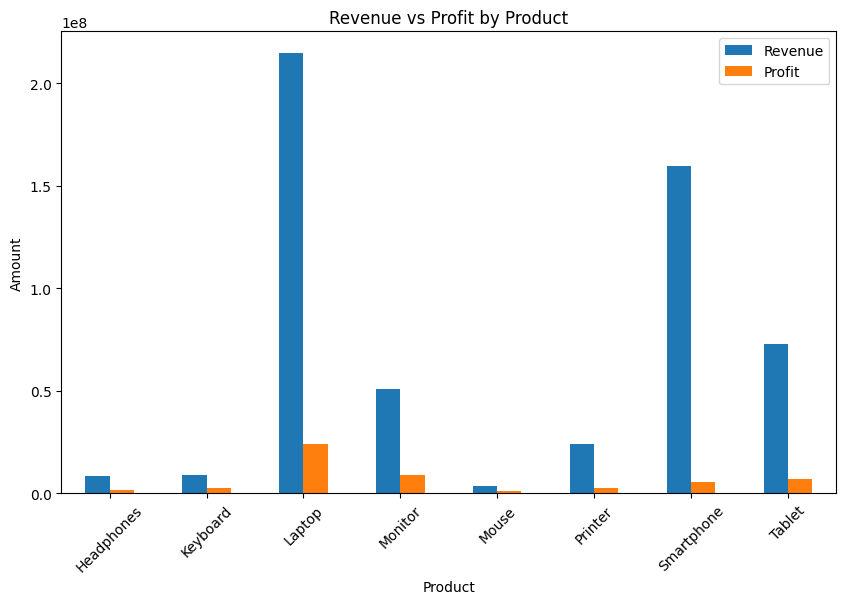

In [29]:
product_plot = df.groupby("Product")[
    ["Revenue", "Profit"]
].sum()

product_plot.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("Revenue vs Profit by Product")
plt.ylabel("Amount")
plt.xticks(rotation=45)
plt.show()

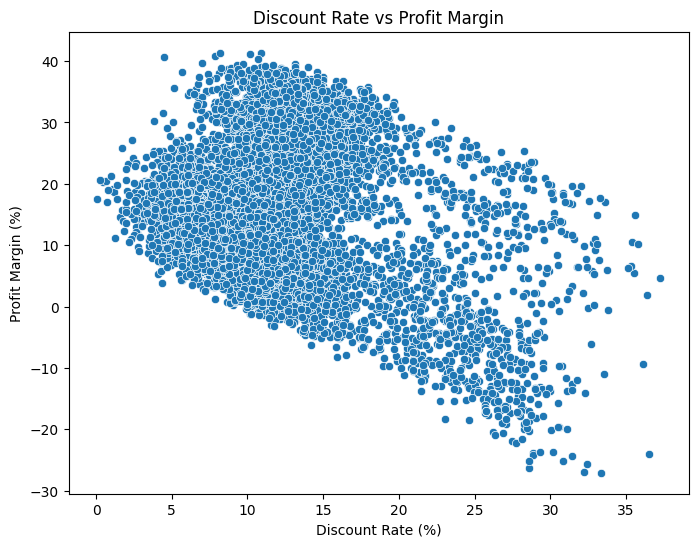

In [30]:
plt.figure(figsize=(8, 6))

sns.scatterplot(
    data=df,
    x="Discount_Rate",
    y="Profit_Margin"
)

plt.title(
    "Discount Rate vs Profit Margin"
)

plt.xlabel("Discount Rate (%)")
plt.ylabel("Profit Margin (%)")

plt.show()

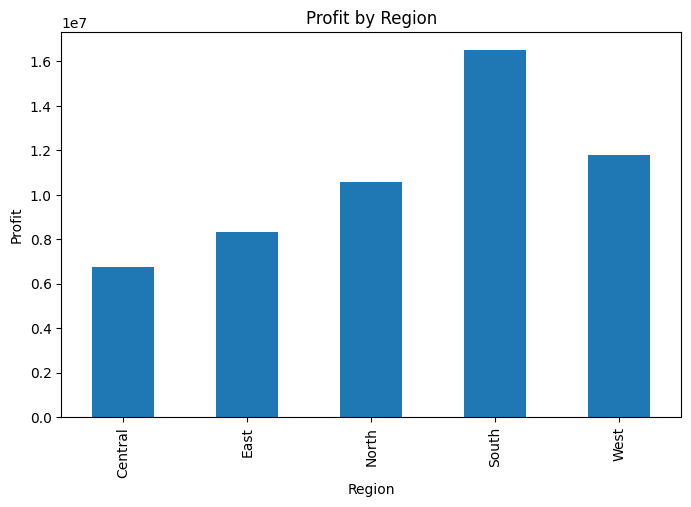

In [31]:
region_plot = df.groupby("Region")[
    "Profit"
].sum()

region_plot.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Profit by Region")
plt.ylabel("Profit")
plt.show()

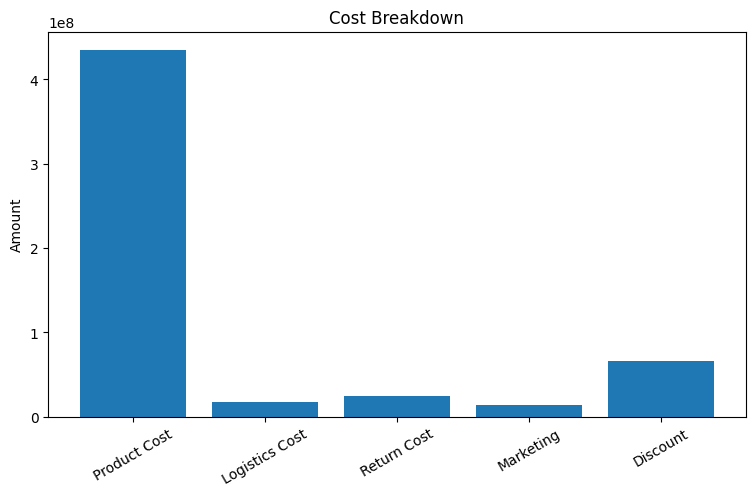

In [32]:
costs = {
    "Product Cost": df["Product_Cost"].sum(),
    "Logistics Cost": df["Logistics_Cost"].sum(),
    "Return Cost": df["Return_Cost"].sum(),
    "Marketing": df["Marketing_Expenditure"].sum(),
    "Discount": df["Discount"].sum()
}

plt.figure(figsize=(9, 5))

plt.bar(
    costs.keys(),
    costs.values()
)

plt.title("Cost Breakdown")
plt.ylabel("Amount")
plt.xticks(rotation=30)

plt.show()

In [33]:
year_analysis = df.groupby("Year").agg({
    "Sales": "sum",
    "Revenue": "sum",
    "Profit": "sum",
    "Discount": "sum",
    "Product_Cost": "sum",
    "Logistics_Cost": "sum",
    "Return_Cost": "sum",
    "Marketing_Expenditure": "sum"
})

year_analysis["Profit_Margin"] = (
    year_analysis["Profit"]
    / year_analysis["Revenue"]
) * 100

year_analysis

,Sales,Revenue,Profit,Discount,Product_Cost,Logistics_Cost,Return_Cost,Marketing_Expenditure,Profit_Margin
Year,,,,,,,,,
2025,3.042011e+08,2.711514e+08,26684071.53,33049715.14,2.174631e+08,8283274.95,11996541.94,6724537.69,9.841023
2026,3.047968e+08,2.721334e+08,27273856.09,32663314.07,2.177074e+08,8406753.53,12016827.80,6728036.48,10.022236


In [34]:
year_analysis.pct_change() * 100

,Sales,Revenue,Profit,Discount,Product_Cost,Logistics_Cost,Return_Cost,Marketing_Expenditure,Profit_Margin
Year,,,,,,,,,
2025,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026,0.195802,0.362171,2.21025,-1.169151,0.112331,1.490698,0.169098,0.05203,1.841409


In [36]:
features = [
    "Sales",
    "Discount",
    "Product_Cost",
    "Logistics_Cost",
    "Return_Cost",
    "Marketing_Expenditure",
    "Product",
    "Region",
    "Customer_Segment"
]

X = df[features]

y = df["Profit"]

In [37]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (8000, 9)
Testing data: (2000, 9)


In [38]:
categorical_features = [
    "Product",
    "Region",
    "Customer_Segment"
]

numerical_features = [
    "Sales",
    "Discount",
    "Product_Cost",
    "Logistics_Cost",
    "Return_Cost",
    "Marketing_Expenditure"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        ),
        (
            "num",
            "passthrough",
            numerical_features
        )
    ]
)

In [39]:
rf = RandomForestRegressor(
    n_estimators=200,
    random_state=42
)

In [40]:
model = Pipeline([
    ("preprocessor", preprocessor),
    ("random_forest", rf)
])

In [41]:
model.fit(
    X_train,
    y_train
)

print("Model trained successfully!")

Model trained successfully!


In [42]:
y_pred = model.predict(X_test)

mae = mean_absolute_error(
    y_test,
    y_pred
)

rmse = np.sqrt(
    mean_squared_error(
        y_test,
        y_pred
    )
)

r2 = r2_score(
    y_test,
    y_pred
)

print("MAE :", mae)
print("RMSE:", rmse)
print("R²  :", r2)

MAE : 1037.63255395
RMSE: 2129.106795732185
R²  : 0.9284446173156864


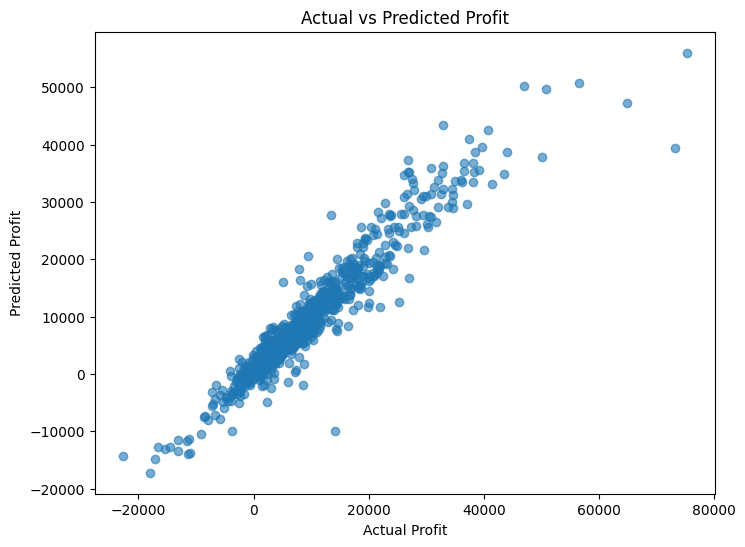

In [43]:
plt.figure(figsize=(8, 6))

plt.scatter(
    y_test,
    y_pred,
    alpha=0.6
)

plt.xlabel("Actual Profit")
plt.ylabel("Predicted Profit")

plt.title(
    "Actual vs Predicted Profit"
)

plt.show()

In [44]:
rf_model = model.named_steps[
    "random_forest"
]

preprocessor_model = model.named_steps[
    "preprocessor"
]

feature_names = (
    preprocessor_model
    .get_feature_names_out()
)

importance = rf_model.feature_importances_

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

importance_df.head(15)

,Feature,Importance
22,num__Marketing_Expenditure,0.444979
18,num__Discount,0.218704
17,num__Sales,0.167037
6,cat__Product_Smartphone,0.108443
3,cat__Product_Monitor,0.014612
21,num__Return_Cost,0.011582
19,num__Product_Cost,0.011298
20,num__Logistics_Cost,0.011070
11,cat__Region_South,0.001537
13,cat__Customer_Segment_Consumer,0.001414


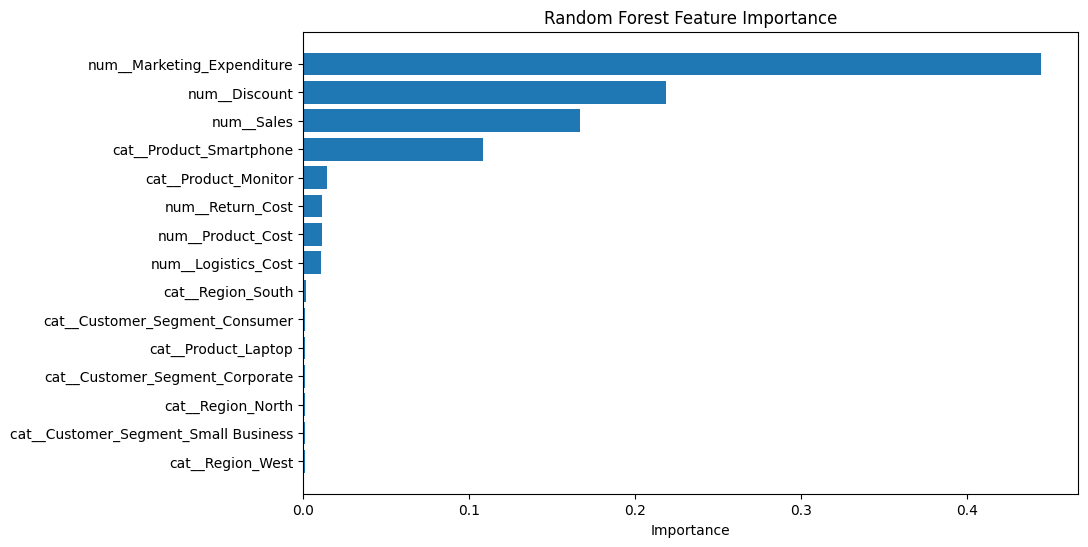

In [45]:
top = importance_df.head(15)

plt.figure(figsize=(10, 6))

plt.barh(
    top["Feature"][::-1],
    top["Importance"][::-1]
)

plt.xlabel("Importance")
plt.title(
    "Random Forest Feature Importance"
)

plt.show()

In [46]:
print("========== FINAL INSIGHTS ==========")

print(
    "1. Total Revenue:",
    df["Revenue"].sum()
)

print(
    "2. Total Profit:",
    df["Profit"].sum()
)

print(
    "3. Overall Profit Margin:",
    round(profit_margin, 2), "%"
)

print(
    "4. Highest Revenue Product:",
    product_analysis["Revenue"].idxmax()
)

print(
    "5. Lowest Margin Product:",
    product_analysis["Profit_Margin"].idxmin()
)

print(
    "6. Highest Profit Region:",
    region_analysis["Profit"].idxmax()
)

print(
    "7. Largest Cost Category:"
)

largest_cost = max(
    costs,
    key=costs.get
)

print(largest_cost)

========== FINAL INSIGHTS ==========
1. Total Revenue: 543284839.42
2. Total Profit: 53957927.62
3. Overall Profit Margin: 9.93 %
4. Highest Revenue Product: Laptop
5. Lowest Margin Product: Smartphone
6. Highest Profit Region: South
7. Largest Cost Category:
Product Cost
